In [1]:
import gc
import re

In [2]:
import textwrap

import matplotlib
import numpy as np
import xarray as xr
from matplotlib import colors as mcol
from matplotlib import pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [3]:
from data import (
    _load_pressure_dataset,
    _load_single_dataset,
    ds_pressure,
    ds_single,
)

In [4]:
from pathlib import Path

plots = Path("plots")

In [5]:
from compression_recommendations import Recommendations
from compression_recommendations.requirements.combinators import (
    AllRequirements,
    AnyRequirement,
)
from compression_recommendations.requirements.error_bounds.max import (
    MaxPointwiseAbsoluteErrorBoundRequirement,
    MaxPointwiseQuadraticErrorBoundRequirement,
    MaxPointwiseRangeRelativeErrorBoundRequirement,
    MaxPointwiseRelativeErrorBoundRequirement,
)
from compression_recommendations.requirements.error_bounds.mean import (
    MeanAbsoluteErrorBoundRequirement,
    MeanRelativeErrorBoundRequirement,
)
from compression_recommendations.requirements.lossless import LosslessRequirement

In [6]:
expert_recommendations = Recommendations.provide

In [7]:
with Path("recommendations", "ensemble-spread.yaml").open("r") as f:
    ensemble_recommendations = Recommendations.load(f)

In [8]:
with Path("recommendations", "bit-information.yaml").open("r") as f:
    bit_information_recommendations = Recommendations.load(f)

In [9]:
with Path("recommendations", "grib-linear-packing.yaml").open("r") as f:
    grib_recommendations = Recommendations.load(f)

In [10]:
def plot_ensemble_mean_spread(
    mean: xr.DataArray,
    spread: xr.DataArray,
    plot: Path,
    extra_markers: dict,
    title_extra: str = "",
):
    mean, spread = mean.copy(deep=True), spread.copy(deep=True)
    meanv, spreadv = mean.values.flatten(), spread.values.flatten()

    amin, amax = np.nanmin(meanv), np.nanmax(meanv)

    fig, ax = plt.subplots(num=1, clear=True)

    m0, m01, m999, m100 = np.nanquantile(meanv, [0.0, 0.001, 0.999, 1.0])
    s99, s100 = np.nanquantile(spreadv, [0.99, 1.0])

    if m01 != m999:
        ms = m999 - m01
        xl, xh = m01 - ms * 0.05, m999 + ms * 0.05
        if xl < 0 and xh > 0 and xl * 2 < -xh and xh * 2 > -xl:
            xl = -max(-xl, xh)
            xh = -xl
        ax.set_xlim(xl, xh)
    elif m100 != m0:
        ms = m100 - m0
        xl, xh = m0 - ms * 0.05, m100 + ms * 0.05
        if xl < 0 and xh > 0 and xl * 2 < -xh and xh * 2 > -xl:
            xl = -max(-xl, xh)
            xh = -xl
        ax.set_xlim(xl, xh)
    else:
        ax.set_xlim(-0.05, 0.05)

    if s99 != 0.0:
        ss = s99
        ax.set_ylim(0.0 - ss * 0.05, s99 + ss * 0.05)
    elif s100 != 0.0:
        ss = s100
        ax.set_ylim(0.0 - ss * 0.05, s100 + ss * 0.05)
    else:
        ax.set_ylim(-0.05, 0.05)

    ax.set_title(
        "\n".join(
            textwrap.wrap(f"{mean.long_name} ({mean.name}){title_extra}", width=45)
        )
    )

    spread_units = re.sub(r"\*\*(-?\d+)", r"$^{\1}$", spread.units)
    ax.set_ylabel(f"spread [{spread_units}]")

    ax.hist2d(
        meanv,
        spreadv,
        bins=[51, 51],
        range=[ax.get_xlim(), ax.get_ylim()],
        cmap="GnBu",
        norm=mcol.LogNorm(),
    )

    bit_information_bound_legend = []

    for p, ls in zip(
        ["100.0%", "99.9%", "99.0%", "95.0%"],
        ["-", "-.", "--", ":"],
    ):
        (bit_information_requirement,) = bit_information_recommendations.search(
            markers={
                "cf-short-name": mean.name,
                "tags": f"{p}",
                **extra_markers,
            }
        )
        assert isinstance(
            bit_information_requirement, MaxPointwiseRelativeErrorBoundRequirement
        )
        x = ax.get_xlim()
        x = np.array(sorted(list(x) + [0.0]))
        bit_information_bound_legend.append(
            ax.plot(
                x,
                np.abs(x) * bit_information_requirement.value,
                ls=ls,
                c="tab:olive",
                lw=2,
                zorder=2,
                label=rf"{p}: $\epsilon_{{rel}}$ = {bit_information_requirement.value:.2%}",
            )[0]
        )

    ensemble_bound_legend = []

    for p, pp, ls in zip(
        ["0.0%", "0.1%", "1.0%", "5.0%"],
        ["0%", "0.1%", "1%", "5%"],
        ["-", "-.", "--", ":"],
    ):
        (ensemble_requirement,) = ensemble_recommendations.search(
            markers={
                "cf-short-name": mean.name,
                "tags": f"pick,{p}",
                **extra_markers,
            }
        )

        if isinstance(ensemble_requirement, MaxPointwiseAbsoluteErrorBoundRequirement):
            ax.axhline(
                ensemble_requirement.value,
                c="white",
                lw=3,
            )
            ensemble_bound_legend.append(
                ax.axhline(
                    ensemble_requirement.value,
                    ls=ls,
                    c="tab:blue",
                    lw=2,
                    zorder=2.5,
                    label=rf"{pp}: $\epsilon_{{abs}}$",
                )
            )
        elif isinstance(
            ensemble_requirement, MaxPointwiseRelativeErrorBoundRequirement
        ):
            x = ax.get_xlim()
            x = np.array(sorted(list(x) + [0.0]))
            ax.plot(
                x,
                np.abs(x) * ensemble_requirement.value,
                c="white",
                lw=3,
            )
            ensemble_bound_legend.append(
                ax.plot(
                    x,
                    np.abs(x) * ensemble_requirement.value,
                    ls=ls,
                    c="tab:orange",
                    lw=2,
                    zorder=2.5,
                    label=rf"{pp}: $\epsilon_{{rel}}$",
                )[0]
            )
        elif isinstance(
            ensemble_requirement, MaxPointwiseQuadraticErrorBoundRequirement
        ):
            x = ax.get_xlim()
            x = np.linspace(x[0], x[1], num=100)
            q, mi, ma = (
                ensemble_requirement.value,
                ensemble_requirement.minimum,
                ensemble_requirement.maximum,
            )
            ax.plot(
                x,
                q - q * (-1.0 + 2.0 * (x - mi) / (ma - mi)) ** 2,
                c="white",
                lw=3,
            )
            ensemble_bound_legend.append(
                ax.plot(
                    x,
                    q - q * (-1.0 + 2.0 * (x - mi) / (ma - mi)) ** 2,
                    ls=ls,
                    c="tab:green",
                    lw=2,
                    zorder=2.5,
                    label=rf"{pp}: $\epsilon_{{qua}}$",
                )[0]
            )
        else:
            assert False, repr(ensemble_requirement)

    grib_bound_legend = []
    (grib_requirement,) = grib_recommendations.search(
        markers={
            "cf-short-name": mean.name,
            **extra_markers,
        }
    )
    assert isinstance(grib_requirement, MaxPointwiseRangeRelativeErrorBoundRequirement)
    ax.axhline(
        grib_requirement.value * (amax - amin),
        c="white",
        lw=3,
    )
    grib_bound_legend.append(
        ax.axhline(
            grib_requirement.value * (amax - amin),
            ls=":",
            c="tab:gray",
            lw=2,
            zorder=2.5,
            label=f"B={-int(np.log2(grib_requirement.value))}",
        )
    )

    expert_bound_legend = []
    expert_requirements = expert_recommendations.search(
        markers={
            "cf-short-name": mean.name,
            **extra_markers,
        }
    )
    # only cover data error bounds in this plot,
    # skip data limit, etc. requirements
    assert len(expert_requirements) >= 1
    assert isinstance(expert_requirements[0], AnyRequirement | AllRequirements)
    expert_combinator = (
        [np.maximum, r" $\lor$ "]
        if isinstance(expert_requirements[0], AnyRequirement)
        else [np.minimum, r" $\land$ "]
    )
    expert_absolute = None
    expert_relative = None
    for expert_requirement in expert_requirements[0].requirements:
        if isinstance(expert_requirement, LosslessRequirement):
            expert_absolute = ["max", 0.0]
            continue
        assert isinstance(expert_requirement, AllRequirements)
        expert_kind = None
        for expert_req in expert_requirement.requirements:
            if isinstance(expert_req, MaxPointwiseAbsoluteErrorBoundRequirement):
                assert expert_kind in ["absolute", None]
                expert_kind = "absolute"
                if expert_absolute is None or expert_absolute[1] >= expert_req.value:
                    expert_absolute = ["max", expert_req.value]
            elif isinstance(expert_req, MeanAbsoluteErrorBoundRequirement):
                assert expert_kind in ["absolute", None]
                expert_kind = "absolute"
                if expert_absolute is None:
                    expert_absolute = ["mean", expert_req.value]
                elif (
                    expert_absolute[0] == "mean"
                    and expert_absolute[1] > expert_req.value
                ):
                    expert_absolute[1] = expert_req.value
            elif isinstance(expert_req, MaxPointwiseRelativeErrorBoundRequirement):
                assert expert_kind in ["relative", None]
                expert_kind = "relative"
                if expert_relative is None or expert_relative[1] >= expert_req.value:
                    expert_relative = ["max", expert_req.value]
            elif isinstance(expert_req, MeanRelativeErrorBoundRequirement):
                assert expert_kind in ["relative", None]
                expert_kind = "relative"
                if expert_relative is None:
                    expert_relative = ["mean", expert_req.value]
                elif (
                    expert_relative[0] == "mean"
                    and expert_relative[1] > expert_req.value
                ):
                    expert_relative[1] = expert_req.value
            elif isinstance(expert_req, LosslessRequirement):
                assert expert_kind in ["absolute", None]
                expert_kind = "absolute"
                expert_absolute = ["max", 0.0]
            else:
                assert False
    x = ax.get_xlim()
    x = np.linspace(x[0], x[1], num=100)
    if expert_absolute is not None:
        y_absolute = np.ones_like(x) * expert_absolute[1]
    if expert_relative is not None:
        y_relative = np.abs(x) * expert_relative[1]
    if expert_absolute is not None and expert_relative is not None:
        y = expert_combinator[0](y_absolute, y_relative)
        expert_label = rf"($\epsilon_{{abs}}$ = {expert_absolute[1]:.2}) {expert_combinator[1]} ($\epsilon_{{rel}}$ = {expert_relative[1]:.2%})"
    elif expert_absolute is not None:
        y = y_absolute
        expert_label = rf"$\epsilon_{{abs}}$ = {expert_absolute[1]:.2}"
    elif expert_relative is not None:
        y = y_relative
        expert_label = rf"$\epsilon_{{rel}}$ = {expert_relative[1]:.2%}"
    else:
        assert False
    expert_bound_legend.append(
        ax.plot(
            x,
            y,
            ls=":",
            c="black",
            lw=2,
            zorder=2.5,
            label=expert_label,
        )[0]
    )

    ax.xaxis.set_major_locator(plt.MaxNLocator(7))

    ax.legend(
        handles=ensemble_bound_legend, loc="upper center", ncols=4, columnspacing=1.5
    )

    divider = make_axes_locatable(ax)

    ax_histx = divider.append_axes("bottom", 0.33, pad=0.15, sharex=ax)
    ax_histx.hist(meanv, bins=51, log=True)
    ax_histx.invert_yaxis()
    mean_units = re.sub(r"\*\*(-?\d+)", r"$^{\1}$", mean.units)
    ax_histx.set_xlabel(f"mean [{mean_units}]")
    ax.xaxis.set_tick_params(which="both", labelbottom=False)

    ax_histy = divider.append_axes("right", 0.33, pad=0.15, sharey=ax)
    ax_histy.hist(spreadv, bins=51, log=True, orientation="horizontal")
    ax_histy.tick_params(axis="x", labelrotation=45)
    ax_histy.yaxis.set_tick_params(which="both", labelleft=False)

    plt.tight_layout()

    plot.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(plot)

    plt.close(fig)

In [11]:
from tqdm import tqdm

In [12]:
for i, key in tqdm(enumerate(sorted(ds_single.mean))):
    if (i > 0) and (i % 50 == 0):
        del ds_single
        gc.collect()
        ds_single = _load_single_dataset()
    plot_ensemble_mean_spread(
        ds_single.mean[key],
        ds_single.spread[key],
        plots / "single" / f"{key}.pdf",
        extra_markers={"level-kind": "single"},
    )

226it [44:53, 11.92s/it]


In [13]:
for i, key in tqdm(enumerate(sorted(ds_pressure.mean))):
    if (i > 0) and (i % 12 == 0):
        del ds_pressure
        gc.collect()
        ds_pressure = _load_pressure_dataset()
    for pressure in sorted(ds_pressure.mean[key].pressure_level.values):
        plot_ensemble_mean_spread(
            ds_pressure.mean[key].sel(pressure_level=pressure),
            ds_pressure.spread[key].sel(pressure_level=pressure),
            plots / "pressure" / f"{key}-{pressure}hPa.pdf",
            extra_markers={"level-kind": "pressure", "level-value": pressure},
            title_extra=f" at {pressure}hPa",
        )

16it [14:37, 54.84s/it]


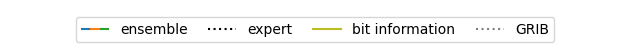

In [14]:
from matplotlib.collections import LineCollection
from matplotlib.legend_handler import HandlerLineCollection

fig, ax = plt.subplots(figsize=(6.4, 0.5), layout="tight")


# adopted from https://stackoverflow.com/a/49224137
class HandlerColorLineCollection(HandlerLineCollection):
    def create_artists(
        self, legend, artist, xdescent, ydescent, width, height, fontsize, trans
    ):
        x = np.linspace(0, width, self.get_numpoints(legend) + 1)
        y = np.zeros(self.get_numpoints(legend) + 1) + height / 2.0 - ydescent
        points = np.array([x, y]).T.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        lc = LineCollection(segments, colors=artist.get_colors(), transform=trans)
        lc.set_array(x)
        lc.set_linewidth(artist.get_linewidth())
        return [lc]


lc = matplotlib.collections.LineCollection(
    [], colors=["tab:blue", "tab:orange", "tab:green"], label="ensemble"
)

ax.legend(
    handles=[
        lc,
        matplotlib.lines.Line2D([0], [0], ls=":", color="black", label="expert"),
        matplotlib.lines.Line2D([0], [0], color="tab:olive", label="bit information"),
        matplotlib.lines.Line2D([0], [0], ls=":", color="tab:gray", label="GRIB"),
    ],
    loc="upper center",
    ncols=4,
    columnspacing=1.5,
    handler_map={lc: HandlerColorLineCollection(numpoints=3)},
)

ax.set_axis_off()

plt.show()
fig.savefig(plots / "legend.pdf")